# PARTIE 1 : AE et VAE sur MNIST

Verifier le gpu 

In [2]:
import torch

print("PyTorch version :", torch.__version__)

print("GPU disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU utilisé :", torch.cuda.get_device_name(0))
else:
    print("Entraînement sur CPU")

PyTorch version : 2.11.0+cu130
GPU disponible : True
GPU utilisé : Tesla T4


In [3]:

# ==========================================
# 1. IMPORTATION DES BIBLIOTHEQUES
# ==========================================

import os
import numpy as np
import matplotlib.pyplot as plt

import torch
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, TensorDataset


In [4]:
for dossier, sous_dossiers, fichiers in os.walk("/kaggle/input"):
    print("Dossier :", dossier)
    for fichier in fichiers:
        print("   ", fichier)

Dossier : /kaggle/input
Dossier : /kaggle/input/datasets
Dossier : /kaggle/input/datasets/hojjatk
Dossier : /kaggle/input/datasets/hojjatk/mnist-dataset
    t10k-images.idx3-ubyte
    t10k-labels.idx1-ubyte
    train-images.idx3-ubyte
    train-labels.idx1-ubyte
Dossier : /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images-idx3-ubyte
    t10k-images-idx3-ubyte
Dossier : /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels-idx1-ubyte
    t10k-labels-idx1-ubyte
Dossier : /kaggle/input/datasets/hojjatk/mnist-dataset/train-images-idx3-ubyte
    train-images-idx3-ubyte
Dossier : /kaggle/input/datasets/hojjatk/mnist-dataset/train-labels-idx1-ubyte
    train-labels-idx1-ubyte


In [5]:

# ==========================================
# 2. EXPLORATION DU DATASET
# ==========================================

DATASET_PATH = "/kaggle/input/datasets/hojjatk/mnist-dataset"

print("Contenu du dossier MNIST :")

for fichier in os.listdir(DATASET_PATH):
    chemin = os.path.join(DATASET_PATH, fichier)

    if os.path.isfile(chemin):
        print(fichier)


Contenu du dossier MNIST :
t10k-images.idx3-ubyte
t10k-labels.idx1-ubyte
train-images.idx3-ubyte
train-labels.idx1-ubyte


Le dataset contient quatre fichiers :
- train-images-idx3-ubyte --> 60 000  images training set 
- train-labels-idx1-ubyte --> labels
- t10k-images-idx3-ubyte --> 10 000 testing set 
- t10k-labels-idx1-ubyte --> labels 

In [6]:

# ==========================================
# 3. CHARGEMENT DU DATASET MNIST
# ==========================================

transform = transforms.ToTensor() # convertir images en tenseurs pytorch 

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Nombre d'images d'entraînement :", len(train_dataset))
print("Nombre d'images de test :", len(test_dataset))


100%|██████████| 9.91M/9.91M [00:02<00:00, 4.40MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 133kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.07MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.52MB/s]

Nombre d'images d'entraînement : 60000
Nombre d'images de test : 10000


In [7]:

# ==========================================
# 4. VERIFICATION DES DIMENSIONS
# ==========================================

image, label = train_dataset[0]

print("Dimension de l'image :", image.shape)
print("Label de l'image :", label)

print("Valeur minimale :", image.min().item())
print("Valeur maximale :", image.max().item())
print("Type des données :", image.dtype)


Dimension de l'image : torch.Size([1, 28, 28])
Label de l'image : 5
Valeur minimale : 0.0
Valeur maximale : 1.0
Type des données : torch.float32


1 28 28  signifie : 1 canal  et 28 en hauteur et 28 en largeur 
1x28x28 = 784  valeurs numeriques

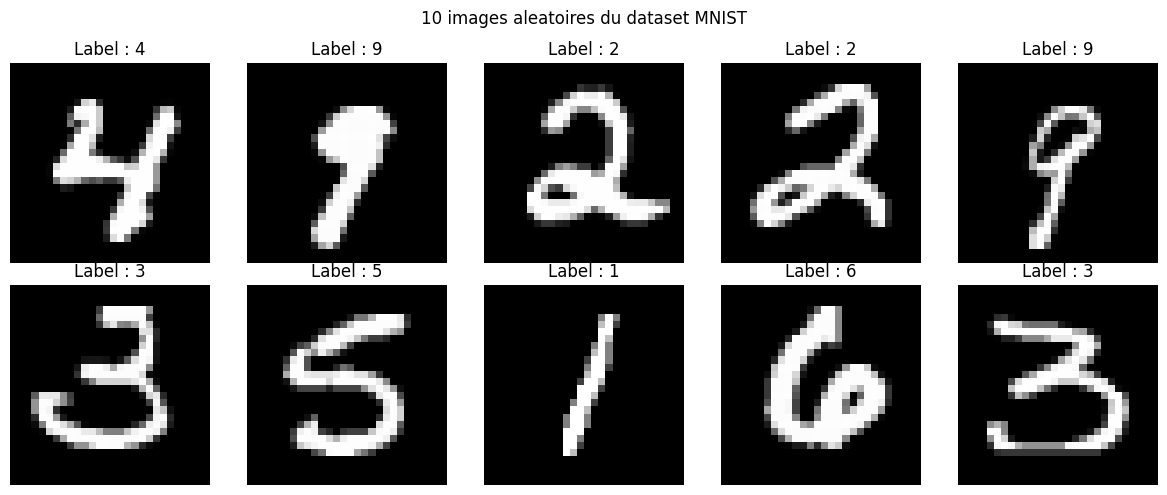

In [8]:

# ==========================================
# 5. AFFICHAGE DE 10 IMAGES ALEATOIRES
# ==========================================

plt.figure(figsize=(12, 5))

# Sélection de 10 indices aléatoires
indices = np.random.choice(
    len(train_dataset),
    size=10,
    replace=False
)

for i, idx in enumerate(indices):

    image, label = train_dataset[idx]

    plt.subplot(2, 5, i + 1)

    # Suppression de la dimension du canal
    plt.imshow(image.squeeze(), cmap="gray")

    plt.title(f"Label : {label}")
    plt.axis("off")

plt.suptitle("10 images aleatoires du dataset MNIST")
plt.tight_layout()
plt.show()


In [9]:

# ==========================================
# 6. CREATION DES DATALOADERS
# ==========================================

BATCH_SIZE = 128

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True # melanger les images d entrainement a chaque epoque 
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False # conserver l ordre des images de test 
)

print("Nombre de batches train :", len(train_loader))
print("Nombre de batches test :", len(test_loader))


Nombre de batches train : 469
Nombre de batches test : 79


ca signifie 469 batches d entrainemnet par epoque  et pour le test 79

In [10]:

# ==========================================
# 7. VERIFICATION D'UN BATCH
# ==========================================

images, labels = next(iter(train_loader))

print("Dimensions des images :", images.shape)
print("Dimensions des labels :", labels.shape)


Dimensions des images : torch.Size([128, 1, 28, 28])
Dimensions des labels : torch.Size([128])


- 128 : nombre d'images.
- 1 : nombre de canaux.
- 28 : hauteur.
- 28 : largeur.

Afficher un resume du dataset 

In [11]:

# ==========================================
# 8. RESUME DU DATASET
# ==========================================

print("========== DATASET MNIST ==========")

print("Images d'entraînement :", len(train_dataset))
print("Images de test :", len(test_dataset))

print("Dimension d'une image :", train_dataset[0][0].shape)

print("Nombre de classes :", len(set(
    train_dataset.targets.tolist()
)))

print("Valeur minimale des pixels :",
      train_dataset[0][0].min().item())

print("Valeur maximale des pixels :",
      train_dataset[0][0].max().item())

print("Batch size :", BATCH_SIZE)

print("===================================")


========== DATASET MNIST ==========
Images d'entraînement : 60000
Images de test : 10000
Dimension d'une image : torch.Size([1, 28, 28])
Nombre de classes : 10
Valeur minimale des pixels : 0.0
Valeur maximale des pixels : 1.0
Batch size : 128


### Construire l auto-encoder 
c est celui qui apprend a construire une image a partir de l espace latent compresse de cette image 
- encoder compresse l image
- latent space conserve representation compresse de l image
- decoder reconstruit image a partir de latent space

  on va faire 1er couche : 784 --> 256
  2eme couche 256 --> 128
  puis 128 --> 32 c est espace latent

In [12]:
# ==========================================
# 1. PREPARATION DES DONNEES POUR L'AE
# ==========================================

# Récupération d'un batch
images, labels = next(iter(train_loader))

# Dimensions du batch
print("Dimensions initiales :", images.shape)

# Transformation de chaque image en vecteur de 784 valeurs
images_flat = images.view(images.size(0), -1)

print("Dimensions après aplatissement :", images_flat.shape)

Dimensions initiales : torch.Size([128, 1, 28, 28])
Dimensions après aplatissement : torch.Size([128, 784])


In [13]:
# Importation des bibliothèques nécessaires

import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import matplotlib.pyplot as plt

In [14]:

# ==========================================
# 2. CONSTRUCTION DE L'AUTOENCODER
# ==========================================

class Autoencoder(nn.Module):

    def __init__(self):
        super(Autoencoder, self).__init__()

        # -------------------------
        # ENCODER
        # -------------------------

        self.encoder = nn.Sequential(

            nn.Linear(784, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, 32)

        )

        # -------------------------
        # DECODER
        # -------------------------

        self.decoder = nn.Sequential(

            nn.Linear(32, 128),
            nn.ReLU(),

            nn.Linear(128, 256),
            nn.ReLU(),

            nn.Linear(256, 784),
            nn.Sigmoid()

        )

    def forward(self, x):

        # Compression
        latent = self.encoder(x)

        # Reconstruction
        reconstructed = self.decoder(latent)

        return reconstructed


Encoder : 
Il effectue progressivement la compression :
- 784 neurones en entrée.
- 256 neurones dans la première couche.
- 128 neurones dans la deuxième couche.
- 32 neurones dans l'espace latent.

Decoder : 
Il effectue l'opération inverse.

Il transforme les 32 valeurs latentes en 784 valeurs correspondant aux pixels reconstruits.

Pourquoi utiliser Sigmoid à la sortie ?

Parce que nos pixels ont été normalisés entre 0 et 1 avec ToTensor().

La fonction Sigmoid garantit donc que les valeurs reconstruites appartiennent également à cet intervalle.

In [15]:
# ==========================================
# 3. INITIALISATION DU MODELE
# ==========================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = Autoencoder().to(device)

print("Device utilisé :", device)

print(model)

Device utilisé : cuda
Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [16]:
# ==========================================
# 4. TEST DU FORWARD PASS
# ==========================================

images, labels = next(iter(train_loader))

# Aplatissement
images = images.view(images.size(0), -1).to(device)

# Passage dans le modèle
with torch.no_grad():
    outputs = model(images)

print("Dimensions entrée :", images.shape)
print("Dimensions sortie :", outputs.shape)

Dimensions entrée : torch.Size([128, 784])
Dimensions sortie : torch.Size([128, 784])


dimension d entree et sortie doivent etre identique 

In [17]:
# ==========================================
# 5. CONFIGURATION DE L'ENTRAINEMENT
# ==========================================

# Fonction de perte
criterion = nn.MSELoss()

# Optimiseur
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Nombre d'époques
EPOCHS = 30

print("Fonction de perte :", criterion)
print("Optimiseur :", optimizer)
print("Nombre d'epochs :", EPOCHS)

Fonction de perte : MSELoss()
Optimiseur : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Nombre d'epochs : 30


Adam adapte automatiquement le taux d'apprentissage des paramètres du réseau pendant l'entraînement.

In [18]:

# ==========================================
# 6. ENTRAINEMENT DE L'AUTOENCODER
# ==========================================

train_losses = []
test_losses = []

for epoch in range(EPOCHS):

    # -------------------------
    # MODE ENTRAINEMENT
    # -------------------------

    model.train() # activer le mode d entrainemnt 

    running_loss = 0.0

    for images, labels in train_loader:

        # Déplacer les images vers le GPU/CPU
        images = images.view(images.size(0), -1).to(device)

        # Remettre les gradients à zéro
        optimizer.zero_grad() # renitialiser les gradients

        # Forward propagation
        reconstructed = model(images)

        # Calcul de la perte
        loss = criterion(reconstructed, images)

        # Backpropagation
        loss.backward()

        # Mise à jour des poids
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_train_loss = running_loss / len(train_loader.dataset)

    train_losses.append(epoch_train_loss)

    # -------------------------
    # MODE EVALUATION
    # -------------------------

    model.eval()

    test_running_loss = 0.0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.view(images.size(0), -1).to(device)

            reconstructed = model(images)

            loss = criterion(reconstructed, images)

            test_running_loss += loss.item() * images.size(0)

    epoch_test_loss = test_running_loss / len(test_loader.dataset)

    test_losses.append(epoch_test_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.6f} "
        f"Test Loss: {epoch_test_loss:.6f}"
    )


Epoch [1/30] Train Loss: 0.049318 Test Loss: 0.027142
Epoch [2/30] Train Loss: 0.023644 Test Loss: 0.020214
Epoch [3/30] Train Loss: 0.018637 Test Loss: 0.016815
Epoch [4/30] Train Loss: 0.015671 Test Loss: 0.014223
Epoch [5/30] Train Loss: 0.013715 Test Loss: 0.012617
Epoch [6/30] Train Loss: 0.012315 Test Loss: 0.011398
Epoch [7/30] Train Loss: 0.011234 Test Loss: 0.010469
Epoch [8/30] Train Loss: 0.010342 Test Loss: 0.009738
Epoch [9/30] Train Loss: 0.009663 Test Loss: 0.009286
Epoch [10/30] Train Loss: 0.009157 Test Loss: 0.008795
Epoch [11/30] Train Loss: 0.008670 Test Loss: 0.008387
Epoch [12/30] Train Loss: 0.008311 Test Loss: 0.008069
Epoch [13/30] Train Loss: 0.007985 Test Loss: 0.007775
Epoch [14/30] Train Loss: 0.007674 Test Loss: 0.007547
Epoch [15/30] Train Loss: 0.007416 Test Loss: 0.007275
Epoch [16/30] Train Loss: 0.007198 Test Loss: 0.007089
Epoch [17/30] Train Loss: 0.006961 Test Loss: 0.006916
Epoch [18/30] Train Loss: 0.006757 Test Loss: 0.006697
Epoch [19/30] Train

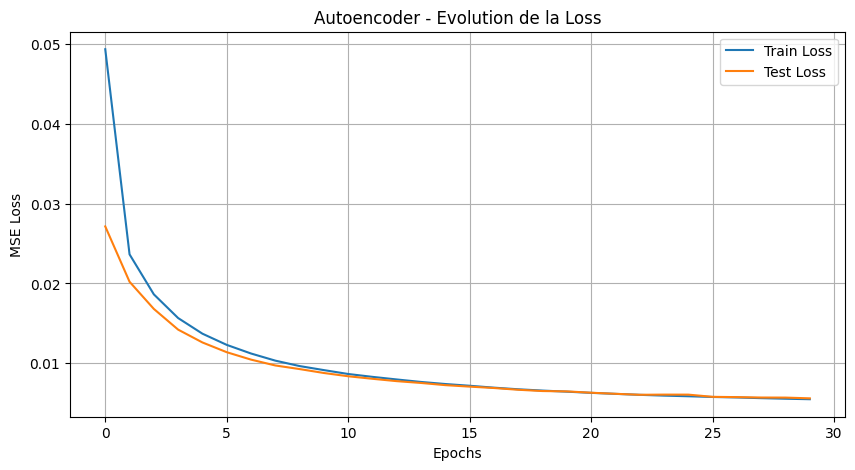

In [19]:
# ==========================================
# 7. VISUALISATION DES COURBES DE LOSS
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Train Loss")
plt.plot(test_losses, label="Test Loss")

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")

plt.title("Autoencoder - Evolution de la Loss")

plt.legend()
plt.grid()

plt.show()

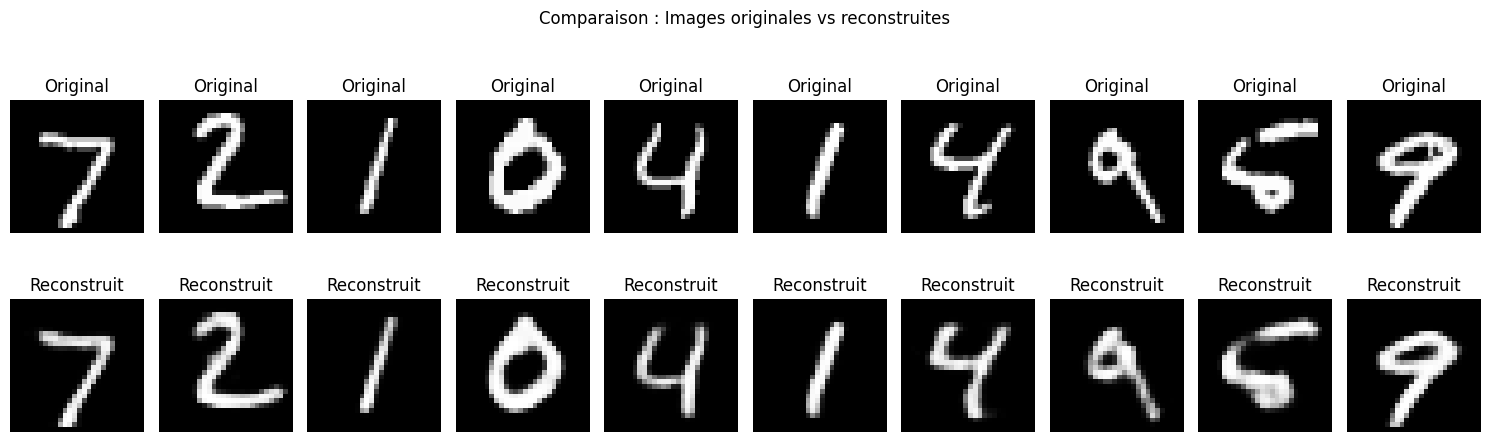

In [20]:

# ==========================================
# 8. COMPARAISON DES IMAGES
# ==========================================

model.eval()

# Récupération de 10 images du dataset de test
images, labels = next(iter(test_loader))

images = images[:10].to(device)

# Aplatissement
images_flat = images.view(images.size(0), -1)

# Reconstruction
with torch.no_grad():
    reconstructed = model(images_flat)

# Retour aux dimensions 28x28
reconstructed = reconstructed.view(-1, 1, 28, 28)

# Affichage
plt.figure(figsize=(15, 5))

for i in range(10):

    # Image originale
    plt.subplot(2, 10, i + 1)

    plt.imshow(
        images[i].cpu().squeeze(),
        cmap="gray"
    )

    plt.title("Original")
    plt.axis("off")

    # Image reconstruite
    plt.subplot(2, 10, i + 11)

    plt.imshow(
        reconstructed[i].cpu().squeeze(),
        cmap="gray"
    )

    plt.title("Reconstruit")
    plt.axis("off")

plt.suptitle("Comparaison : Images originales vs reconstruites")

plt.tight_layout()
plt.show()


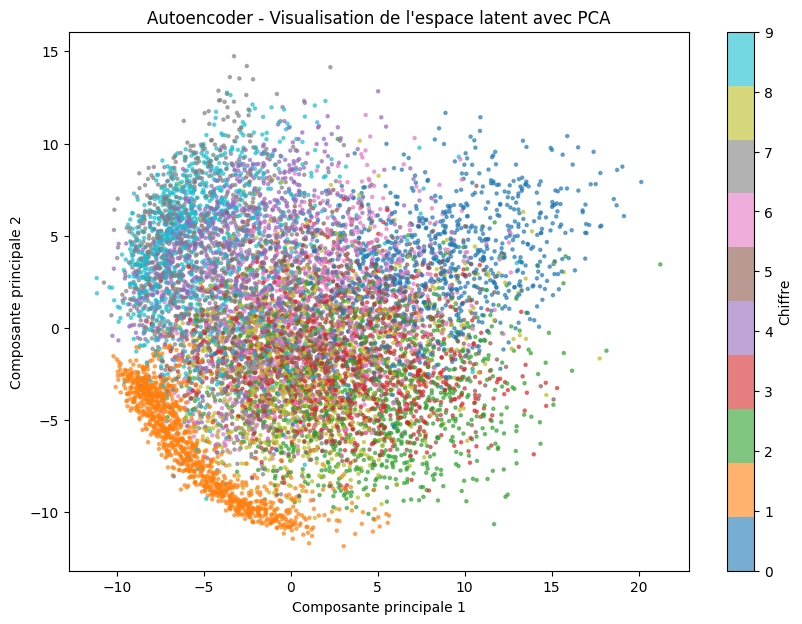

In [21]:

# ==========================================
# 9. VISUALISATION DE L'ESPACE LATENT
# ==========================================

from sklearn.decomposition import PCA

model.eval()

latent_vectors = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.view(images.size(0), -1).to(device)

        # Extraction des representations latentes
        latent = model.encoder(images)

        latent_vectors.append(latent.cpu().numpy())

        all_labels.append(labels.numpy())

# Concatenation
latent_vectors = np.concatenate(latent_vectors)
all_labels = np.concatenate(all_labels)

# Reduction de 32 dimensions a 2 dimensions
pca = PCA(n_components=2)

latent_2d = pca.fit_transform(latent_vectors)

# Affichage
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=all_labels,
    cmap="tab10",
    s=5,
    alpha=0.6
)

plt.colorbar(scatter, label="Chiffre")

plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")

plt.title("Autoencoder - Visualisation de l'espace latent avec PCA")

plt.show()


verifions les resultats 

In [22]:
print("Dimensions des vecteurs latents :", latent_vectors.shape)
print("Dimensions après PCA :", latent_2d.shape)
print("Nombre de labels :", all_labels.shape)
print("Variance expliquée par PCA :", pca.explained_variance_ratio_)
print("Variance totale expliquée :", sum(pca.explained_variance_ratio_))

Dimensions des vecteurs latents : (10000, 32)
Dimensions après PCA : (10000, 2)
Nombre de labels : (10000,)
Variance expliquée par PCA : [0.16442917 0.11618521]
Variance totale expliquée : 0.28061438


- on a traite 10 000 images  et chaque image est representee par un veteur de 32 valeurs (de 784 a 32)
- pca transforme 32 dim en 2 composantes principales
- 10 000 etiquettes pour chaque image
- PCA cherche les directions qui conservent le plus d'informations concernant la dispersion des données
- les 2 composantes conserve environ 28% de la variance presente dans 32 dim
- Les 28% sont une mesure de la qualité de représentation de la projection PCA en 2D, pas une mesure de performance de reconstruction de l'Autoencoder

# Variational Autoencoder (VAE) avec MNIST

In [24]:
# ==========================================
# 1. ARCHITECTURE DU VARIATIONAL AUTOENCODER
# ==========================================

import torch
import torch.nn as nn
import torch.nn.functional as F

class VAE(nn.Module):

    def __init__(self, latent_dim=32):
        super(VAE, self).__init__()

        # ENCODEUR qui recoit une image MNIST de 784 valeurs  
        # il use 2 couches (256 puis 128) il va produire 2 soties 
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 128)

        # Moyenne et log-variance
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        # DECODEUR
        self.fc3 = nn.Linear(latent_dim, 128)
        self.fc4 = nn.Linear(128, 256)
        self.fc5 = nn.Linear(256, 784)

    # Encodeur
    def encode(self, x):

        h = F.relu(self.fc1(x))
        h = F.relu(self.fc2(h))

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar

    # Reparameterization trick
    def reparameterize(self, mu, logvar):

        std = torch.exp(0.5 * logvar)

        eps = torch.randn_like(std)

        z = mu + eps * std

        return z

    # Décodeur
    def decode(self, z):

        h = F.relu(self.fc3(z))
        h = F.relu(self.fc4(h))

        return torch.sigmoid(self.fc5(h))

    # Forward
    def forward(self, x):

        mu, logvar = self.encode(x)

        z = self.reparameterize(mu, logvar)

        reconstruction = self.decode(z)

        return reconstruction, mu, logvar

In [25]:
# ==========================================
# 2. INITIALISATION DU VAE
# ==========================================

latent_dim = 32

vae = VAE(latent_dim).to(device)

print(vae)

print("Device utilisé :", device)

VAE(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc_mu): Linear(in_features=128, out_features=32, bias=True)
  (fc_logvar): Linear(in_features=128, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=128, bias=True)
  (fc4): Linear(in_features=128, out_features=256, bias=True)
  (fc5): Linear(in_features=256, out_features=784, bias=True)
)
Device utilisé : cuda


couches encodeurs :
- 1er couche : recoit 784 - pixels de image 
- 2eme couche : 256 extrait les caracteristiques 
- fc_mu : 128 --> 32 produit la moyenne 
- fc_logvar : 128 --> 32 produit logvar 

couches de decodeur :
- fc3: 32 recoit vecteur latent z
- fc4 : 128 developpe la representation
- fc5 : 256 produit 784 pixels de image reconstruite
- derniere couche use sigmoid pour ramener les pixels entre 0 et 1 

In [26]:
# ==========================================
# 3. TEST DU FORWARD PASS
# ==========================================

images, labels = next(iter(train_loader))

images = images.view(images.size(0), -1).to(device)

reconstruction, mu, logvar = vae(images)

print("Images originales :", images.shape)
print("Reconstruction :", reconstruction.shape)
print("Moyenne (mu) :", mu.shape)
print("Log-variance :", logvar.shape)

Images originales : torch.Size([128, 784])
Reconstruction : torch.Size([128, 784])
Moyenne (mu) : torch.Size([128, 32])
Log-variance : torch.Size([128, 32])


- chaque image de 28 x 28 transformer en vecteur de 784 valeurs
- le decodeur a produit 128 images reconstruites et chaque image possede 784 valeurs  objectif du VAE est de reconstruire les images originales avec meme dim
- Pour chacune des 128 images encodeur calcule un vecteur de moyenne de 32 valeurs
- encodeur calcule  un 2eme  vecteur de 32 valeurs pour chaque image Il represente le logarithme de la variance de la distribution latente ( car VAE ne veut pas seulement connaitre la position de image dans espace latent mais apprendre la variabilite autor de cette position )

In [28]:
# --------------------------------------------------------------------------------------------------------------
# Calcul erreur globale du model pendant entrainement : reuissite de VAE = equilibre entre 2 objectifs opposes 
# --------------------------------------------------------------------------------------------------------------
def vae_loss(recon_x, x, mu, logvar):

    # 1. Perte de reconstruction : a quelle point image reconstruite rassemble a image originale 
    recon_loss = F.binary_cross_entropy(
        recon_x,
        x,
        reduction="sum"
    )

    # 2. Divergence KL : mesure la distance entre distribution predite par encodeur et la loi normale standard centree reduite 
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    # 3. Perte totale moyenne par image
    total_loss = (recon_loss + kl_loss) / x.size(0)

    return total_loss, recon_loss / x.size(0), kl_loss / x.size(0)


les 2 objectis : copier fidelement image d entree , tout en gardant un espace latent bien organise pour pouvoir generer de nouvelles images 

In [29]:
# Configurere l optimizer : Adam 

# Hyperparamètres
learning_rate = 0.001
epochs = 30

# Optimiseur Adam
optimizer = optim.Adam(
    vae.parameters(),
    lr=learning_rate
)

print("Optimiseur :", optimizer)
print("Nombre d'epochs :", epochs)


Optimiseur : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Nombre d'epochs : 30


In [31]:
# Entrainer VAE 

# sauvgarder historiques des erreurs a chaque epoque 
train_losses = []
train_recon_losses = []
train_kl_losses = []

for epoch in range(epochs):

    vae.train() # activer mode entrainemnet 

    total_epoch_loss = 0
    total_epoch_recon = 0
    total_epoch_kl = 0

    # on ignore labels car but de vae est de recopier image entree et pas savoir quelle est image 
    for images, labels in train_loader:

        # Envoyer les images sur le GPU
        images = images.view(images.size(0), -1).to(device)

        # Reinitialiser les gradients
        optimizer.zero_grad()

        # Passage avant
        reconstruction, mu, logvar = vae(images)

        # Calcul de la fonction de perte
        loss, recon_loss, kl_loss = vae_loss(
            reconstruction, images, mu, logvar
        )

        # backpropagation
        loss.backward()

        # update des param
        optimizer.step()

        # Accumuler les pertes 
        batch_size = images.size(0)

        total_epoch_loss += loss.item() * batch_size
        total_epoch_recon += recon_loss.item() * batch_size
        total_epoch_kl += kl_loss.item() * batch_size

    # Moyenne sur tout le dataset
    n_samples = len(train_loader.dataset)

    epoch_loss = total_epoch_loss / n_samples
    epoch_recon = total_epoch_recon / n_samples
    epoch_kl = total_epoch_kl / n_samples

    train_losses.append(epoch_loss)
    train_recon_losses.append(epoch_recon)
    train_kl_losses.append(epoch_kl)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {epoch_loss:.4f} | "
        f"Reconstruction: {epoch_recon:.4f} | "
        f"KL: {epoch_kl:.4f}"
    )


Epoch [1/30] Loss: 101.6161 | Reconstruction: 81.3852 | KL: 20.2309
Epoch [2/30] Loss: 101.5517 | Reconstruction: 81.2922 | KL: 20.2595
Epoch [3/30] Loss: 101.3833 | Reconstruction: 81.1289 | KL: 20.2545
Epoch [4/30] Loss: 101.3184 | Reconstruction: 81.0463 | KL: 20.2721
Epoch [5/30] Loss: 101.2517 | Reconstruction: 80.9370 | KL: 20.3147
Epoch [6/30] Loss: 101.0990 | Reconstruction: 80.7913 | KL: 20.3077
Epoch [7/30] Loss: 101.0806 | Reconstruction: 80.7364 | KL: 20.3442
Epoch [8/30] Loss: 100.9733 | Reconstruction: 80.6397 | KL: 20.3336
Epoch [9/30] Loss: 100.8575 | Reconstruction: 80.5177 | KL: 20.3398
Epoch [10/30] Loss: 100.7915 | Reconstruction: 80.4282 | KL: 20.3634
Epoch [11/30] Loss: 100.7637 | Reconstruction: 80.3914 | KL: 20.3723
Epoch [12/30] Loss: 100.6091 | Reconstruction: 80.2438 | KL: 20.3653
Epoch [13/30] Loss: 100.5753 | Reconstruction: 80.1703 | KL: 20.4050
Epoch [14/30] Loss: 100.5217 | Reconstruction: 80.1238 | KL: 20.3979
Epoch [15/30] Loss: 100.4991 | Reconstructi

on remarque que les loss ne deminue pas trops donc j ai decider d ajouter 30 epochs supplementaires 

In [33]:

# Nombre d'epochs supplementaires
additional_epochs = 30

# Continuer entrainement a partir du model actuel
for epoch in range(additional_epochs):

    vae.train()

    total_epoch_loss = 0
    total_epoch_recon = 0
    total_epoch_kl = 0

    for images, labels in train_loader:

        images = images.view(images.size(0), -1).to(device)

        optimizer.zero_grad()

        reconstruction, mu, logvar = vae(images)

        loss, recon_loss, kl_loss = vae_loss(
            reconstruction, images, mu, logvar
        )

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)

        total_epoch_loss += loss.item() * batch_size
        total_epoch_recon += recon_loss.item() * batch_size
        total_epoch_kl += kl_loss.item() * batch_size

    n_samples = len(train_loader.dataset)

    epoch_loss = total_epoch_loss / n_samples
    epoch_recon = total_epoch_recon / n_samples
    epoch_kl = total_epoch_kl / n_samples

    train_losses.append(epoch_loss)
    train_recon_losses.append(epoch_recon)
    train_kl_losses.append(epoch_kl)

    print(
        f"Epoch [{30 + epoch + 1}/60] "
        f"Loss: {epoch_loss:.4f} | "
        f"Reconstruction: {epoch_recon:.4f} | "
        f"KL: {epoch_kl:.4f}"
    )


Epoch [31/60] Loss: 99.6647 | Reconstruction: 79.1353 | KL: 20.5294
Epoch [32/60] Loss: 99.6173 | Reconstruction: 79.0668 | KL: 20.5506
Epoch [33/60] Loss: 99.5006 | Reconstruction: 78.9849 | KL: 20.5157
Epoch [34/60] Loss: 99.5636 | Reconstruction: 79.0148 | KL: 20.5488
Epoch [35/60] Loss: 99.5306 | Reconstruction: 78.9738 | KL: 20.5568
Epoch [36/60] Loss: 99.4380 | Reconstruction: 78.8741 | KL: 20.5640
Epoch [37/60] Loss: 99.4630 | Reconstruction: 78.8913 | KL: 20.5717
Epoch [38/60] Loss: 99.3695 | Reconstruction: 78.7964 | KL: 20.5732
Epoch [39/60] Loss: 99.3508 | Reconstruction: 78.7797 | KL: 20.5711
Epoch [40/60] Loss: 99.3304 | Reconstruction: 78.7615 | KL: 20.5690
Epoch [41/60] Loss: 99.2628 | Reconstruction: 78.7050 | KL: 20.5578
Epoch [42/60] Loss: 99.2267 | Reconstruction: 78.6648 | KL: 20.5619
Epoch [43/60] Loss: 99.2647 | Reconstruction: 78.6819 | KL: 20.5828
Epoch [44/60] Loss: 99.2296 | Reconstruction: 78.6384 | KL: 20.5912
Epoch [45/60] Loss: 99.1752 | Reconstruction: 78

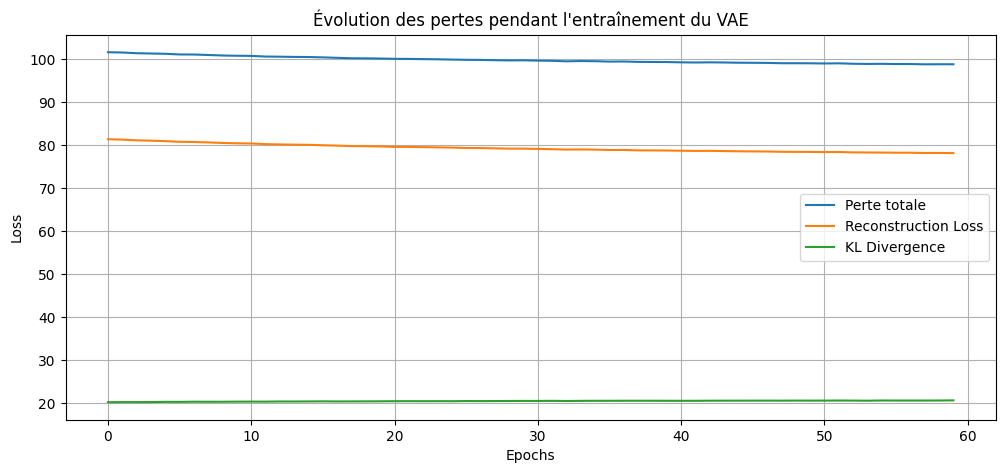

In [34]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(train_losses, label="Perte totale")
plt.plot(train_recon_losses, label="Reconstruction Loss")
plt.plot(train_kl_losses, label="KL Divergence")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Évolution des pertes pendant l'entraînement du VAE")

plt.legend()
plt.grid(True)
plt.show()

In [35]:
# Evaluer le VAE sur les donnees de test 
vae.eval()

test_total_loss = 0
test_recon_loss = 0
test_kl_loss = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.view(images.size(0), -1).to(device)

        reconstruction, mu, logvar = vae(images)

        loss, recon, kl = vae_loss(
            reconstruction, images, mu, logvar
        )

        batch_size = images.size(0)

        test_total_loss += loss.item() * batch_size
        test_recon_loss += recon.item() * batch_size
        test_kl_loss += kl.item() * batch_size

n_test = len(test_loader.dataset)

test_total_loss /= n_test
test_recon_loss /= n_test
test_kl_loss /= n_test

print("Résultats sur les données de test :")
print(f"Perte totale         : {test_total_loss:.4f}")
print(f"Reconstruction Loss  : {test_recon_loss:.4f}")
print(f"KL Divergence        : {test_kl_loss:.4f}")


Résultats sur les données de test :
Perte totale         : 100.0337
Reconstruction Loss  : 79.2509
KL Divergence        : 20.7828


- La perte totale a diminue pendant training.
- La perte de reconstruction a progressivement diminue.
- Les pertes d'entraînement et de test sont relativement proches.
- y a pas de signe evident de overfitting importanta partir de ces results.

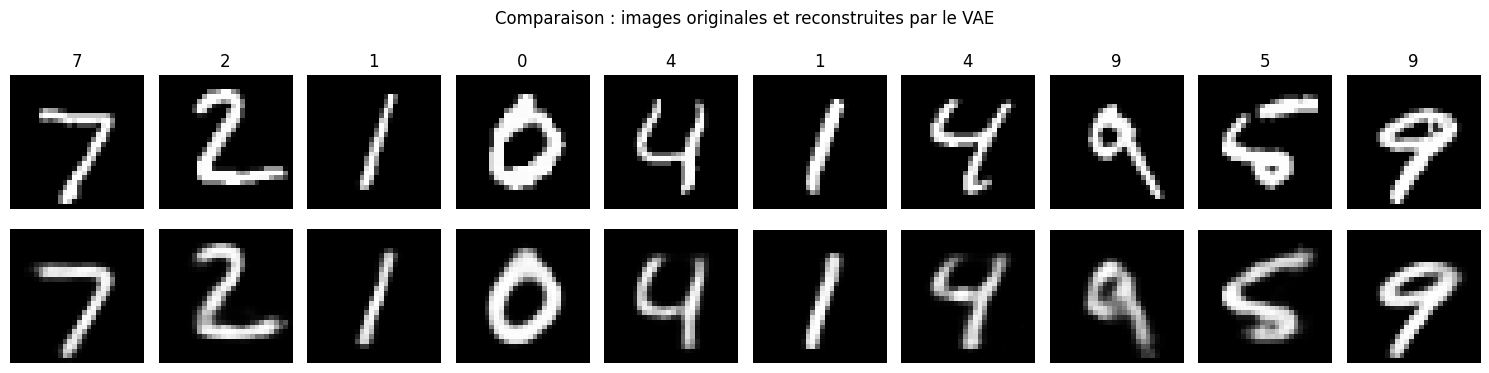

In [36]:
# comparer entre images originales et construites 

import matplotlib.pyplot as plt

vae.eval()

images, labels = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    images_flat = images.view(images.size(0), -1)
    reconstruction, mu, logvar = vae(images_flat)

# Afficher les 10 premières images
fig, axes = plt.subplots(2, 10, figsize=(15, 4))

for i in range(10):

    # Images originales
    axes[0, i].imshow(
        images[i].squeeze().cpu().numpy(),
        cmap="gray"
    )
    axes[0, i].axis("off")
    axes[0, i].set_title(f"{labels[i].item()}")

    # Images reconstruites
    axes[1, i].imshow(
        reconstruction[i].view(28, 28).cpu().numpy(),
        cmap="gray"
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Originales")
axes[1, 0].set_ylabel("Reconstruites")

plt.suptitle("Comparaison : images originales et reconstruites par le VAE")
plt.tight_layout()
plt.show()


on essaye de generer des nouveaux chiffres avec VAE 


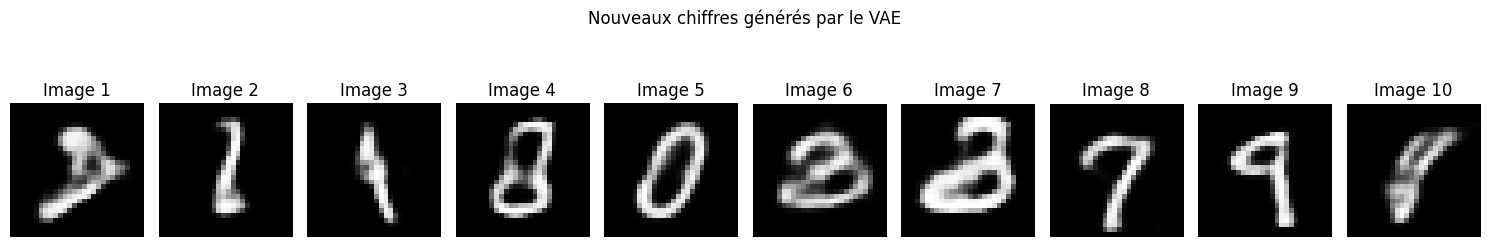

In [37]:

import torch
import matplotlib.pyplot as plt

# Mettre le VAE en mode evaluation
vae.eval()

# Nombre images a generer
num_images = 10

# generer des vecteurs latents aleatoires
with torch.no_grad():

    z = torch.randn(num_images, 32).to(device)

    # Passer les vecteurs ds le decoder
    generated_images = vae.decode(z)

# Afficher les images generees
fig, axes = plt.subplots(1, num_images, figsize=(15, 3))

for i in range(num_images):

    axes[i].imshow(
        generated_images[i].view(28, 28).cpu().numpy(),
        cmap="gray"
    )

    axes[i].axis("off")
    axes[i].set_title(f"Image {i+1}")

plt.suptitle("Nouveaux chiffres générés par le VAE")
plt.tight_layout()
plt.show()


Les resultats  obtenus montrent que le model est capable de generer de nouvelles images ressemblant aux chiffres manuscrits de MNIST. Certaines images sont facilement reconnaissables,  mais autres ont des formes floues. ca montre  la capacité generative du VAE.

visualiser espace latent avec PCA 

In [38]:

import numpy as np
import torch

vae.eval()

latent_vectors_vae = []
labels_vae = []

with torch.no_grad():

    for images, labels in test_loader:

        # Envoyer les images sur le GPU
        images = images.view(images.size(0), -1).to(device)

        # Extraire mu et logvar
        mu, logvar = vae.encode(images)

        # Conserver les moyennes latentes
        latent_vectors_vae.append(mu.cpu().numpy())

        # Conserver les labels
        labels_vae.append(labels.numpy())

# Transformer les listes en tableaux NumPy
latent_vectors_vae = np.concatenate(latent_vectors_vae, axis=0)
labels_vae = np.concatenate(labels_vae, axis=0)

print("Dimensions des vecteurs latents :", latent_vectors_vae.shape)
print("Dimensions des labels :", labels_vae.shape)


Dimensions des vecteurs latents : (10000, 32)
Dimensions des labels : (10000,)


In [39]:

from sklearn.decomposition import PCA

# creer un model PCA avec 2 composantes
pca_vae = PCA(n_components=2)

# reduire dim
latent_2d_vae = pca_vae.fit_transform(latent_vectors_vae)

print("Dimensions après PCA :", latent_2d_vae.shape)

print("Variance expliquée par PCA :",
      pca_vae.explained_variance_ratio_)

print("Variance totale expliquée :",
      sum(pca_vae.explained_variance_ratio_))


Dimensions après PCA : (10000, 2)
Variance expliquée par PCA : [0.10445759 0.09896491]
Variance totale expliquée : 0.20342249


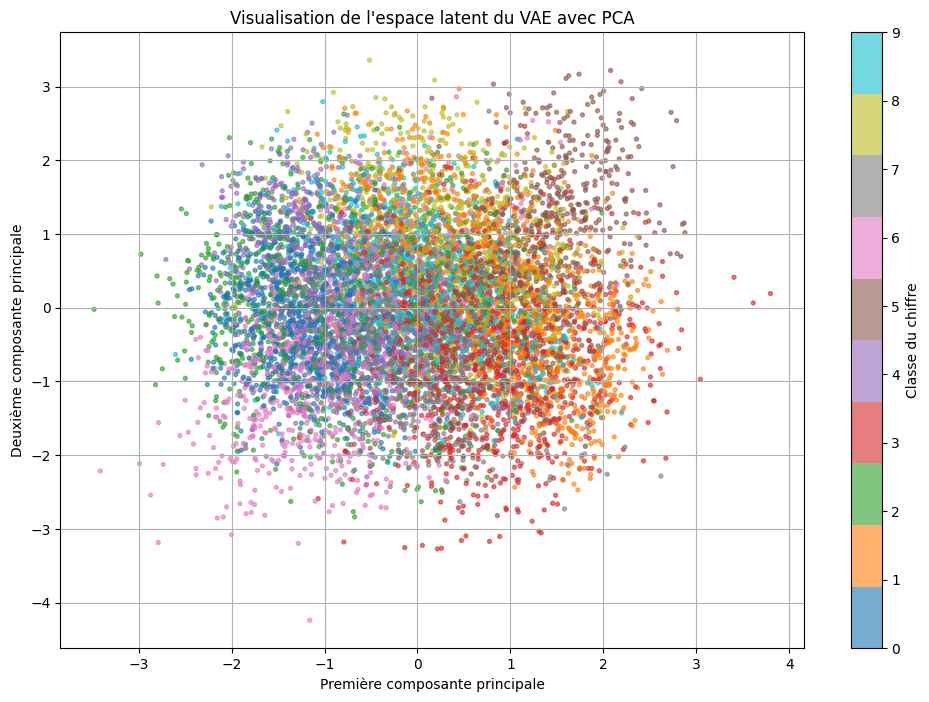

In [40]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    latent_2d_vae[:, 0],
    latent_2d_vae[:, 1],
    c=labels_vae,
    cmap="tab10",
    alpha=0.6,
    s=8
)

plt.colorbar(scatter, label="Classe du chiffre")

plt.xlabel("Première composante principale")
plt.ylabel("Deuxième composante principale")

plt.title("Visualisation de l'espace latent du VAE avec PCA")

plt.grid(True)
plt.show()


# Conclusion
 les experiences de reconstruction et de generation ont mis en evidence une difference fondamentale entre les deux approches : AE est principalement adapte a la reconstruction des donnees, alors que le VAE possede une capacite supp de generatin de nouvelles images a partir de vecteurs latents echantillonnas randomly.